# TrustTriage: calibrated, cost-aware medical image triage with shift monitoring

**Question:** when a missed disease costs far more than a false alarm, how should a medical image classifier choose its decisions, know when to hand a case to a clinician, and notice when its data has changed?

This notebook answers that on two public MedMNIST tasks:

* **BreastMNIST** (breast ultrasound, malignant vs normal/benign)
* **PneumoniaMNIST** (chest X-ray, pneumonia vs normal)

For each task it:

1. trains a **logistic-regression baseline** and a **convolutional neural network (PyTorch)**;
2. measures **calibration** (Brier score, expected calibration error) and fixes it with **Platt scaling** (a logistic recalibration of the network's outputs) fitted on the validation set;
3. sets the decision threshold from the **cost of each error** (a missed positive costs 5x a false alarm), comparing a threshold tuned on validation data with the theoretical cost-optimal threshold that calibrated probabilities make possible;
4. adds **selective prediction**: the least certain cases are **deferred to a clinician**, giving a risk-coverage curve;
5. simulates a **deployment shift** (blur, lower contrast, noise) and detects it **without labels** using a **kernel two-sample test (MMD)** on the network's embeddings.

**How to run in Google Colab:** `Runtime > Run all`. A GPU is optional (`Runtime > Change runtime type`); on CPU the whole notebook takes a few minutes.



In [1]:
# Install the MedMNIST data package (PyTorch, scikit-learn and matplotlib are already in Colab)
%pip install -q medmnist

## 1. Setup and configuration

In [2]:
import os, json, math, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve

CFG = {
    "datasets": ["breastmnist", "pneumoniamnist"],
    "image_size": 28,          # MedMNIST also offers 64, 128, 224 (slower)
    "epochs": 40,
    "batch_size": 64,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "patience": 8,             # early stopping on validation loss
    "min_epochs": 5,
    "cost_fn": 5.0,            # cost of a missed positive (false negative)
    "cost_fp": 1.0,            # cost of a false alarm (false positive)
    "coverage_target": 0.8,    # fraction of cases decided automatically; the rest go to a clinician
    "shift_levels": [0, 1, 2, 3],
    "mmd_batch": 50,           # size of each simulated deployment batch
    "mmd_ref_max": 200,        # reference sample size for the shift test
    "mmd_trials": 20,
    "mmd_perms": 100,
    "alpha": 0.05,
    "seed": 0,
    "data_root": "./data",
    "out_dir": "./results",
}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(CFG["seed"])
os.makedirs(CFG["out_dir"], exist_ok=True)
os.makedirs(CFG["data_root"], exist_ok=True)
print("Device:", DEVICE, "| PyTorch", torch.__version__)

Device: cuda | PyTorch 2.14.1+cu130


## 2. Data loading
The positive class is found from MedMNIST's own label names (malignant, pneumonia). If the download fails, a clearly labelled synthetic stand-in is used so the code still runs; its results are **not** real.

In [3]:
def _to_nchw(x):
    x = x.astype(np.float32) / 255.0
    if x.ndim == 3:                      # (N, H, W) grayscale
        x = x[:, None, :, :]
    elif x.ndim == 4:                    # (N, H, W, C) colour
        x = np.transpose(x, (0, 3, 1, 2))
    return x

def _positive_index(label_names):
    keywords = ("malignant", "pneumonia", "tumor", "abnormal", "disease")
    for key, name in label_names.items():
        if any(w in name.lower() for w in keywords):
            return int(key)
    raise ValueError(f"Could not identify the positive class in {label_names}")

def _synthetic(n, size, rng, pos_rate=0.3):
    X = rng.normal(0.45, 0.12, (n, 1, size, size)).astype(np.float32)
    y = (rng.random(n) < pos_rate).astype(int)
    yy, xx = np.mgrid[0:size, 0:size]
    for i in np.where(y == 1)[0]:
        cy, cx = rng.integers(size // 4, 3 * size // 4, 2)
        r = rng.uniform(size / 10, size / 6)
        X[i, 0] += 0.35 * np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * r * r))
    return np.clip(X, 0, 1).astype(np.float32), y

def load_dataset(flag, size, root):
    try:
        import medmnist
        info = medmnist.INFO[flag]
        DataClass = getattr(medmnist, info["python_class"])
        pos = _positive_index(info["label"])
        out = {}
        for split in ("train", "val", "test"):
            try:
                ds = DataClass(split=split, download=False, size=size, root=root)
            except Exception:
                ds = DataClass(split=split, download=True, size=size, root=root)
            X = _to_nchw(np.asarray(ds.imgs))
            y = (np.asarray(ds.labels).reshape(-1).astype(int) == pos).astype(int)
            out[split] = (X, y)
        out["positive_name"] = info["label"][str(pos)]
        out["synthetic"] = False
        return out
    except Exception as e:
        print(f"WARNING: could not load {flag} ({type(e).__name__}: {str(e)[:80]}). "
              "Using SYNTHETIC data; these results are NOT real.")
        rng = np.random.default_rng(0)
        sizes = {"breastmnist": (546, 78, 156), "pneumoniamnist": (4708, 524, 624)}.get(flag, (1000, 200, 300))
        out = {s: _synthetic(n, size, rng) for s, n in zip(("train", "val", "test"), sizes)}
        out["positive_name"] = "synthetic positive"
        out["synthetic"] = True
        return out

## 3. Models: logistic-regression baseline and a small CNN

In [4]:
def fit_logreg(train, val, test):
    Xtr, ytr = train
    scaler = StandardScaler().fit(Xtr.reshape(len(Xtr), -1))
    flat = lambda X: scaler.transform(X.reshape(len(X), -1))
    clf = LogisticRegression(max_iter=3000, C=0.05)
    clf.fit(flat(Xtr), ytr)
    return {"val": clf.predict_proba(flat(val[0]))[:, 1],
            "test": clf.predict_proba(flat(test[0]))[:, 1]}

class SmallCNN(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_ch, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, 1))

    def embed(self, x):
        return self.features(x).flatten(1)

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

@torch.no_grad()
def predict_logits(model, X, bs=512):
    model.eval()
    out = [model(torch.from_numpy(X[i:i + bs]).to(DEVICE)).cpu() for i in range(0, len(X), bs)]
    return torch.cat(out).numpy().astype(np.float64)

@torch.no_grad()
def embed(model, X, bs=512):
    model.eval()
    out = [model.embed(torch.from_numpy(X[i:i + bs]).to(DEVICE)).cpu() for i in range(0, len(X), bs)]
    return torch.cat(out).numpy().astype(np.float64)

def train_cnn(train, val, cfg):
    Xtr = torch.from_numpy(train[0]); ytr = torch.from_numpy(train[1].astype(np.float32))
    model = SmallCNN(Xtr.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    gen = torch.Generator().manual_seed(cfg["seed"])
    best_loss, best_state, bad, epochs_run = float("inf"), None, 0, 0
    yv_t = torch.from_numpy(val[1].astype(np.float64))
    for epoch in range(cfg["epochs"]):
        model.train()
        perm = torch.randperm(len(Xtr), generator=gen)
        for i in range(0, len(Xtr), cfg["batch_size"]):
            idx = perm[i:i + cfg["batch_size"]]
            xb, yb = Xtr[idx].to(DEVICE), ytr[idx].to(DEVICE)
            flip = torch.rand(len(xb), device=DEVICE) < 0.5          # augmentation: random horizontal flip
            xb = torch.where(flip[:, None, None, None], xb.flip(-1), xb)
            loss = F.binary_cross_entropy_with_logits(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
        epochs_run = epoch + 1
        v_logits = predict_logits(model, val[0])
        val_loss = float(F.binary_cross_entropy_with_logits(torch.from_numpy(v_logits), yv_t))
        if val_loss < best_loss - 1e-4:
            best_loss, bad = val_loss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= cfg["patience"] and epochs_run >= cfg["min_epochs"]:
                break
    model.load_state_dict(best_state)
    model.eval()
    best_auc = float(roc_auc_score(val[1], predict_logits(model, val[0])))
    return model, epochs_run, best_auc

## 4. Metrics, calibration and cost-aware thresholds

In [5]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def ece_score(y, p, bins=15):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    ece = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(ece)

def at_threshold(y, p, t, cfn, cfp):
    pred = p >= t
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    n = len(y)
    return {"threshold": float(t), "sensitivity": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1),
            "accuracy": (tp + tn) / n, "FN": fn, "FP": fp, "cost_per_case": (cfn * fn + cfp * fp) / n}

def full_metrics(y, p, t, cfn, cfp):
    d = at_threshold(y, p, t, cfn, cfp)
    d.update({"auc": float(roc_auc_score(y, p)), "brier": float(np.mean((p - y) ** 2)), "ece": ece_score(y, p)})
    return d

def fit_platt(logits, y):
    """Platt scaling: p = sigmoid(a * logit + b), fitted on validation data. a > 0 keeps the ranking (and AUC)."""
    z = torch.tensor(logits, dtype=torch.float64); yt = torch.tensor(y, dtype=torch.float64)
    log_a = torch.zeros(1, dtype=torch.float64, requires_grad=True)
    b = torch.zeros(1, dtype=torch.float64, requires_grad=True)
    opt = torch.optim.LBFGS([log_a, b], lr=0.1, max_iter=500)
    def closure():
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(torch.exp(log_a) * z + b, yt)
        loss.backward()
        return loss
    opt.step(closure)
    return float(torch.exp(log_a).item()), float(b.item())

def best_threshold(y, p, cfn, cfp):
    grid = np.round(np.linspace(0.01, 0.99, 99), 2)
    costs = np.array([at_threshold(y, p, t, cfn, cfp)["cost_per_case"] for t in grid])
    return float(grid[int(np.argmin(costs))]), grid, costs

## 5. Selective prediction: defer the least certain cases to a clinician

In [6]:
def selective(y, p, t, cfn, cfp):
    """Rank cases by the expected cost of the action the model would take; automate the most certain ones."""
    pred = (p >= t).astype(int)
    exp_cost = np.where(pred == 1, cfp * (1 - p), cfn * p)
    order = np.argsort(exp_cost)
    n = len(y)
    cov, cost, missed = [], [], []
    for k in range(1, n + 1):
        idx = order[:k]
        fn = int(((pred[idx] == 0) & (y[idx] == 1)).sum())
        fp = int(((pred[idx] == 1) & (y[idx] == 0)).sum())
        cov.append(k / n); cost.append((cfn * fn + cfp * fp) / k); missed.append(fn)
    return np.array(cov), np.array(cost), np.array(missed)

def at_coverage(y, p, t, cfn, cfp, target):
    cov, cost, missed = selective(y, p, t, cfn, cfp)
    k = int(math.ceil(target * len(y))) - 1
    return {"coverage": float(cov[k]), "deferred_cases": int(len(y) - (k + 1)),
            "auto_cost_per_case": float(cost[k]), "missed_positives_in_automated": int(missed[k]),
            "missed_positives_full_automation": int(missed[-1])}

## 6. Deployment shift and label-free monitoring with a kernel two-sample test (MMD)

In [7]:
def apply_shift(X, level, seed=0):
    """Simulated scanner/protocol change: Gaussian blur, lower contrast and added noise."""
    if level == 0:
        return X.copy()
    x = torch.from_numpy(X).double()
    sigma = 0.5 * level
    k = int(2 * math.ceil(2 * sigma) + 1)
    ax = torch.arange(k, dtype=torch.float64) - k // 2
    g = torch.exp(-ax ** 2 / (2 * sigma ** 2)); g = g / g.sum()
    c = x.shape[1]
    kx = g.view(1, 1, 1, k).repeat(c, 1, 1, 1); ky = g.view(1, 1, k, 1).repeat(c, 1, 1, 1)
    x = F.conv2d(F.pad(x, (k // 2, k // 2, 0, 0), mode="reflect"), kx, groups=c)
    x = F.conv2d(F.pad(x, (0, 0, k // 2, k // 2), mode="reflect"), ky, groups=c)
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = mean + (1 - 0.15 * level) * (x - mean)
    gen = torch.Generator().manual_seed(seed + level)
    x = x + 0.03 * level * torch.randn(x.shape, generator=gen, dtype=torch.float64)
    return x.clamp(0, 1).float().numpy()

def _mmd2_unbiased(K, n):
    m = K.shape[0] - n
    kxx, kyy, kxy = K[:n, :n], K[n:, n:], K[:n, n:]
    sxx = (kxx.sum() - np.trace(kxx)) / (n * (n - 1))
    syy = (kyy.sum() - np.trace(kyy)) / (m * (m - 1))
    return sxx + syy - 2 * kxy.mean()

def mmd_test(ref, test, perms, rng):
    z = np.vstack([ref, test]); n = len(ref)
    sq = (z ** 2).sum(1)
    d = np.maximum(sq[:, None] + sq[None, :] - 2 * z @ z.T, 0)
    dref = d[:n, :n]
    bw = np.median(dref[dref > 0])               # bandwidth fixed from the reference set (median heuristic)
    K = np.exp(-d / bw)
    stat = _mmd2_unbiased(K, n)
    hits = 0
    for _ in range(perms):
        idx = rng.permutation(len(z))
        if _mmd2_unbiased(K[np.ix_(idx, idx)], n) >= stat:
            hits += 1
    return float(stat), (hits + 1) / (perms + 1)

## 7. Figures

In [8]:
def reliability_points(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    xs, ys = [], []
    for b in range(bins):
        m = idx == b
        if m.sum() >= 3:
            xs.append(p[m].mean()); ys.append(y[m].mean())
    return np.array(xs), np.array(ys)

def make_figure(flag, R, yt, p_lr, pt_raw, pt, grid, val_costs, test_costs, sel, shift_rows, path):
    fig, axs = plt.subplots(2, 3, figsize=(16, 9.5))
    ax = axs[0, 0]
    for name, p in (("Logistic regression", p_lr), ("CNN", pt)):
        fpr, tpr, _ = roc_curve(yt, p)
        ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(yt, p):.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set(title="ROC curve (test)", xlabel="False positive rate", ylabel="True positive rate"); ax.legend()
    ax = axs[0, 1]
    for name, p in (("CNN before calibration", pt_raw), ("CNN after Platt scaling", pt)):
        xs, ys = reliability_points(yt, p)
        ax.plot(xs, ys, "o-", label=f"{name} (ECE {ece_score(yt, p):.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set(title="Reliability diagram (test)", xlabel="Predicted probability", ylabel="Observed frequency"); ax.legend()
    ax = axs[0, 2]
    ax.plot(grid, val_costs, label="Validation"); ax.plot(grid, test_costs, label="Test")
    ax.axvline(R["thresholds"]["tuned_on_validation"], color="g", ls="--", label=f"Tuned on validation ({R['thresholds']['tuned_on_validation']:.2f})")
    ax.axvline(R["thresholds"]["cost_optimal_theory"], color="r", ls=":", label=f"Cost-optimal theory ({R['thresholds']['cost_optimal_theory']:.2f})")
    ax.axvline(0.5, color="gray", ls="-.", label="Default 0.5")
    ax.set(title=f"Expected cost per case (missed positive = {CFG['cost_fn']:g} x false alarm)", xlabel="Decision threshold", ylabel="Cost per case"); ax.legend(fontsize=8)
    ax = axs[1, 0]
    cov, cost, _ = sel
    ax.plot(cov, cost); ax.axvline(CFG["coverage_target"], color="gray", ls="--")
    ax.set(title="Selective prediction: cost of automated decisions", xlabel="Coverage (fraction decided automatically)", ylabel="Cost per automated case")
    ax = axs[1, 1]
    levels = [r["level"] for r in shift_rows]
    ax.plot(levels, [r["detection_rate"] for r in shift_rows], "o-", label="MMD detection rate")
    ax.axhline(CFG["alpha"], color="gray", ls=":", label=f"alpha = {CFG['alpha']}")
    ax.set(title="Label-free shift detection", xlabel="Shift severity", ylabel="Fraction of batches flagged", ylim=(-0.05, 1.05)); ax.legend()
    ax = axs[1, 2]
    ax.plot(levels, [r["auc"] for r in shift_rows], "o-", label="AUC")
    ax2 = ax.twinx(); ax2.plot(levels, [r["cost_per_case"] for r in shift_rows], "s--", color="tab:red", label="Cost per case")
    ax.set(title="Performance under shift (needs labels)", xlabel="Shift severity", ylabel="AUC"); ax2.set_ylabel("Cost per case")
    fig.suptitle(f"TrustTriage on {flag} ({R['positive_class']} as positive)" + ("  [SYNTHETIC DATA]" if R["synthetic_data"] else ""), fontsize=14)
    fig.tight_layout(); fig.savefig(path, dpi=130); plt.show(); plt.close(fig)

## 8. Run the full experiment

100%|██████████| 560k/560k [00:01<00:00, 514kB/s]



=== breastmnist: train 546, val 78, test 156 | positive = malignant (27% of test) ===


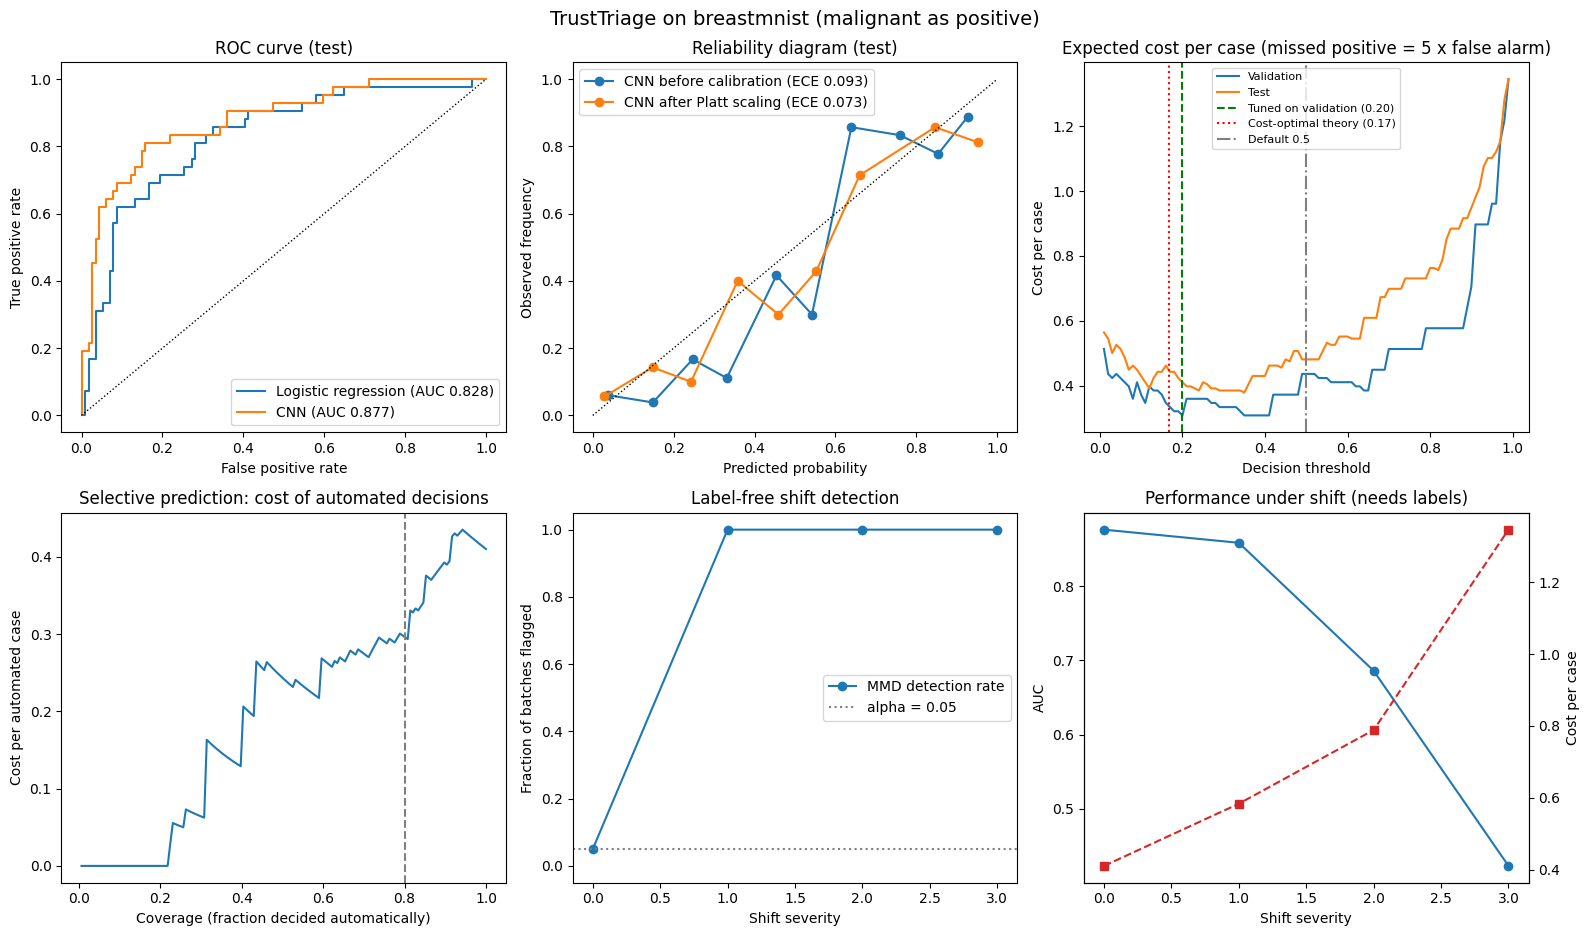

100%|██████████| 4.17M/4.17M [00:05<00:00, 696kB/s]



=== pneumoniamnist: train 4708, val 524, test 624 | positive = pneumonia (62% of test) ===


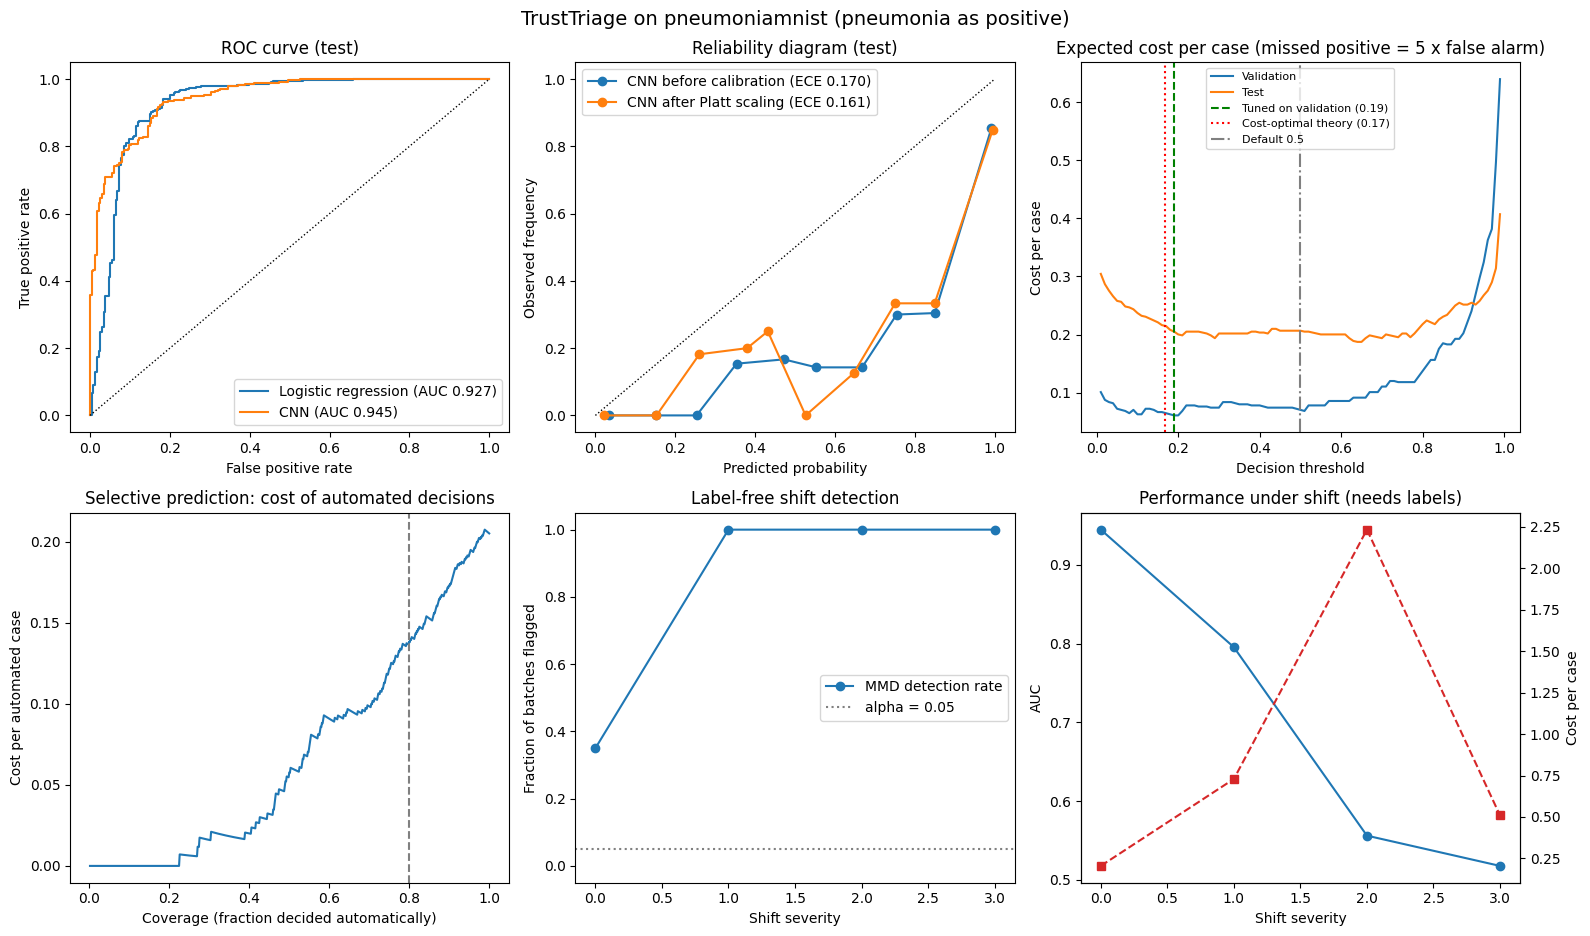

In [9]:
def run_dataset(flag):
    set_seed(CFG["seed"]); t0 = time.time()
    cfn, cfp = CFG["cost_fn"], CFG["cost_fp"]
    data = load_dataset(flag, CFG["image_size"], CFG["data_root"])
    tr, va, te = data["train"], data["val"], data["test"]
    yv, yt = va[1], te[1]
    print(f"\n=== {flag}: train {len(tr[1])}, val {len(yv)}, test {len(yt)} | positive = {data['positive_name']} "
          f"({yt.mean():.0%} of test) ===")

    p_lr = fit_logreg(tr, va, te)
    model, epochs_run, best_val_auc = train_cnn(tr, va, CFG)
    lv, lt = predict_logits(model, va[0]), predict_logits(model, te[0])
    pv_raw, pt_raw = sigmoid(lv), sigmoid(lt)
    platt_a, platt_b = fit_platt(lv, yv)
    calib = lambda z: sigmoid(platt_a * z + platt_b)
    pv, pt = calib(lv), calib(lt)

    t_val, grid, val_costs = best_threshold(yv, pv, cfn, cfp)
    test_costs = np.array([at_threshold(yt, pt, t, cfn, cfp)["cost_per_case"] for t in grid])
    t_theory = cfp / (cfp + cfn)

    models = {
        "Logistic regression @0.5": full_metrics(yt, p_lr["test"], 0.5, cfn, cfp),
        "CNN @0.5 (uncalibrated)": full_metrics(yt, pt_raw, 0.5, cfn, cfp),
        "CNN @0.5 (calibrated)": full_metrics(yt, pt, 0.5, cfn, cfp),
        "CNN @cost-optimal theory (uncalibrated)": full_metrics(yt, pt_raw, t_theory, cfn, cfp),
        "CNN @cost-optimal theory (calibrated)": full_metrics(yt, pt, t_theory, cfn, cfp),
        "CNN @tuned on validation (calibrated)": full_metrics(yt, pt, t_val, cfn, cfp),
    }
    sel = selective(yt, pt, t_val, cfn, cfp)
    sel_summary = at_coverage(yt, pt, t_val, cfn, cfp, CFG["coverage_target"])

    rng = np.random.default_rng(CFG["seed"])
    ref_idx = rng.choice(len(yv), size=min(CFG["mmd_ref_max"], len(yv)), replace=False)
    ref_emb = embed(model, va[0][ref_idx])
    shift_rows = []
    for level in CFG["shift_levels"]:
        Xs = apply_shift(te[0], level, seed=CFG["seed"])
        ps = calib(predict_logits(model, Xs))
        emb = embed(model, Xs)
        flags = []
        for _ in range(CFG["mmd_trials"]):
            batch = rng.choice(len(yt), size=min(CFG["mmd_batch"], len(yt)), replace=False)
            _, pval = mmd_test(ref_emb, emb[batch], CFG["mmd_perms"], rng)
            flags.append(pval < CFG["alpha"])
        m = at_threshold(yt, ps, t_val, cfn, cfp)
        shift_rows.append({"level": level, "auc": float(roc_auc_score(yt, ps)), "cost_per_case": m["cost_per_case"],
                           "FN": m["FN"], "detection_rate": float(np.mean(flags))})

    R = {"dataset": flag, "positive_class": data["positive_name"], "synthetic_data": data["synthetic"],
         "n": {"train": int(len(tr[1])), "val": int(len(yv)), "test": int(len(yt))},
         "cnn": {"epochs_run": epochs_run, "best_val_auc": float(best_val_auc), "platt_a": platt_a, "platt_b": platt_b},
         "thresholds": {"default": 0.5, "cost_optimal_theory": t_theory, "tuned_on_validation": t_val},
         "test_metrics": models, "selective_prediction": sel_summary, "shift": shift_rows,
         "runtime_s": round(time.time() - t0, 1)}
    os.makedirs(os.path.join(CFG["out_dir"], flag), exist_ok=True)
    make_figure(flag, R, yt, p_lr["test"], pt_raw, pt, grid, val_costs, test_costs, sel, shift_rows,
                os.path.join(CFG["out_dir"], flag, "summary.png"))
    return R

ALL = {flag: run_dataset(flag) for flag in CFG["datasets"]}

## 9. Results tables (also saved to `results/summary.md` and `results/metrics.json`)

In [10]:
def fmt_table(R):
    lines = [f"### {R['dataset']} ({R['positive_class']} as positive; missed positive = {CFG['cost_fn']:g} x false alarm)",
             "" if not R["synthetic_data"] else "**WARNING: synthetic stand-in data; not real results.**", "",
             f"CNN: {R['cnn']['epochs_run']} epochs, best validation AUC {R['cnn']['best_val_auc']:.3f}, "
             f"Platt scaling a = {R['cnn']['platt_a']:.2f}, b = {R['cnn']['platt_b']:.2f}", "",
             "| Model and threshold | AUC | Brier | ECE | Threshold | Sensitivity | Specificity | Missed positives | False alarms | Cost per case |",
             "|---|---|---|---|---|---|---|---|---|---|"]
    for name, m in R["test_metrics"].items():
        lines.append(f"| {name} | {m['auc']:.3f} | {m['brier']:.3f} | {m['ece']:.3f} | {m['threshold']:.2f} | "
                     f"{m['sensitivity']:.1%} | {m['specificity']:.1%} | {m['FN']} | {m['FP']} | {m['cost_per_case']:.3f} |")
    s = R["selective_prediction"]
    lines += ["", f"Selective prediction at {s['coverage']:.0%} coverage: {s['deferred_cases']} cases deferred to a clinician; "
                  f"missed positives among automated decisions {s['missed_positives_in_automated']} "
                  f"(vs {s['missed_positives_full_automation']} if everything were automated); "
                  f"automated cost per case {s['auto_cost_per_case']:.3f}.", "",
              "| Shift severity | AUC | Cost per case | Missed positives | MMD detection rate |", "|---|---|---|---|---|"]
    for r in R["shift"]:
        lines.append(f"| {r['level']} | {r['auc']:.3f} | {r['cost_per_case']:.3f} | {r['FN']} | {r['detection_rate']:.0%} |")
    lines.append(f"\n(Severity 0 is no shift, so its detection rate is the false-alarm rate; target about {CFG['alpha']:.0%}.)\n")
    return "\n".join(lines)

report = "# TrustTriage results\n\n" + "\n\n".join(fmt_table(R) for R in ALL.values())
with open(os.path.join(CFG["out_dir"], "summary.md"), "w") as f:
    f.write(report)
with open(os.path.join(CFG["out_dir"], "metrics.json"), "w") as f:
    json.dump({"config": CFG, "results": ALL}, f, indent=2)
print(report)
print("Saved:", os.path.abspath(CFG["out_dir"]))

# TrustTriage results

### breastmnist (malignant as positive; missed positive = 5 x false alarm)


CNN: 40 epochs, best validation AUC 0.926, Platt scaling a = 1.40, b = -0.06

| Model and threshold | AUC | Brier | ECE | Threshold | Sensitivity | Specificity | Missed positives | False alarms | Cost per case |
|---|---|---|---|---|---|---|---|---|---|
| Logistic regression @0.5 | 0.828 | 0.145 | 0.089 | 0.50 | 42.9% | 93.0% | 24 | 8 | 0.821 |
| CNN @0.5 (uncalibrated) | 0.877 | 0.119 | 0.093 | 0.50 | 69.0% | 89.5% | 13 | 12 | 0.494 |
| CNN @0.5 (calibrated) | 0.877 | 0.116 | 0.073 | 0.50 | 69.0% | 91.2% | 13 | 10 | 0.481 |
| CNN @cost-optimal theory (uncalibrated) | 0.877 | 0.119 | 0.093 | 0.17 | 90.5% | 56.1% | 4 | 50 | 0.449 |
| CNN @cost-optimal theory (calibrated) | 0.877 | 0.116 | 0.073 | 0.17 | 83.3% | 70.2% | 7 | 34 | 0.442 |
| CNN @tuned on validation (calibrated) | 0.877 | 0.116 | 0.073 | 0.20 | 83.3% | 74.6% | 7 | 29 | 0.410 |

Selective prediction at 80% coverage: 31 cases d

## 10. Findings

* **Cost-aware thresholds work.** On breast ultrasound, calibrating the CNN and choosing the threshold on validation data cut missed malignancies from 13 to 7 of 42 (sensitivity 69.0% to 83.3%), at the cost of 17 more false alarms, and lowered cost per case from 0.481 to 0.410. The theoretical cost-optimal threshold came close (0.442).
* **Deferral helps.** Sending the least certain 20% of breast cases to a clinician cut missed malignancies among automated decisions from 7 to 4.
* **Monitoring catches shift early.** The MMD test flagged every batch at the mildest simulated shift, where AUC barely moved (0.877 to 0.859) but cost per case rose by 42%, with a 5% false-alarm rate on clean data.
* **Validation can mislead.** On PneumoniaMNIST, validation AUC was 0.996 but test AUC was 0.945, and the MMD test flagged 35% of clean test batches against the validation data. This suggests the test images differ from the validation images, and it explains why calibration fitted on validation barely helped on the test set. On cost, the CNN matched the logistic-regression baseline without beating it.

